# Ray Tracing
Following the ray tracing by hand with three principal rays, we can programmatically draw a ray parallel to the axis passing through the focus, a ray through the near focus emerging parallel to the axis, and a ray through the center of the lens undeviated.

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

## Define variables

In [2]:
# --- Parameters (Default values from your code) ---
f = 10.0      # Focal Length
s_o = 15.0    # Object Distance
h_o = 10.0    # Object Height

# --- Physics Calculations ---
# Thin lens equation: 1/f = 1/s_o + 1/s_i  => s_i = (f * s_o) / (s_o - f)
if abs(s_o - f) < 0.1:
    s_i = np.inf
    h_i = np.inf
else:
    s_i = (f * s_o) / (s_o - f)

# Magnification: M = -s_i / s_o
h_i = (-s_i / s_o) * h_o if np.isfinite(s_i) else np.inf

## Plot

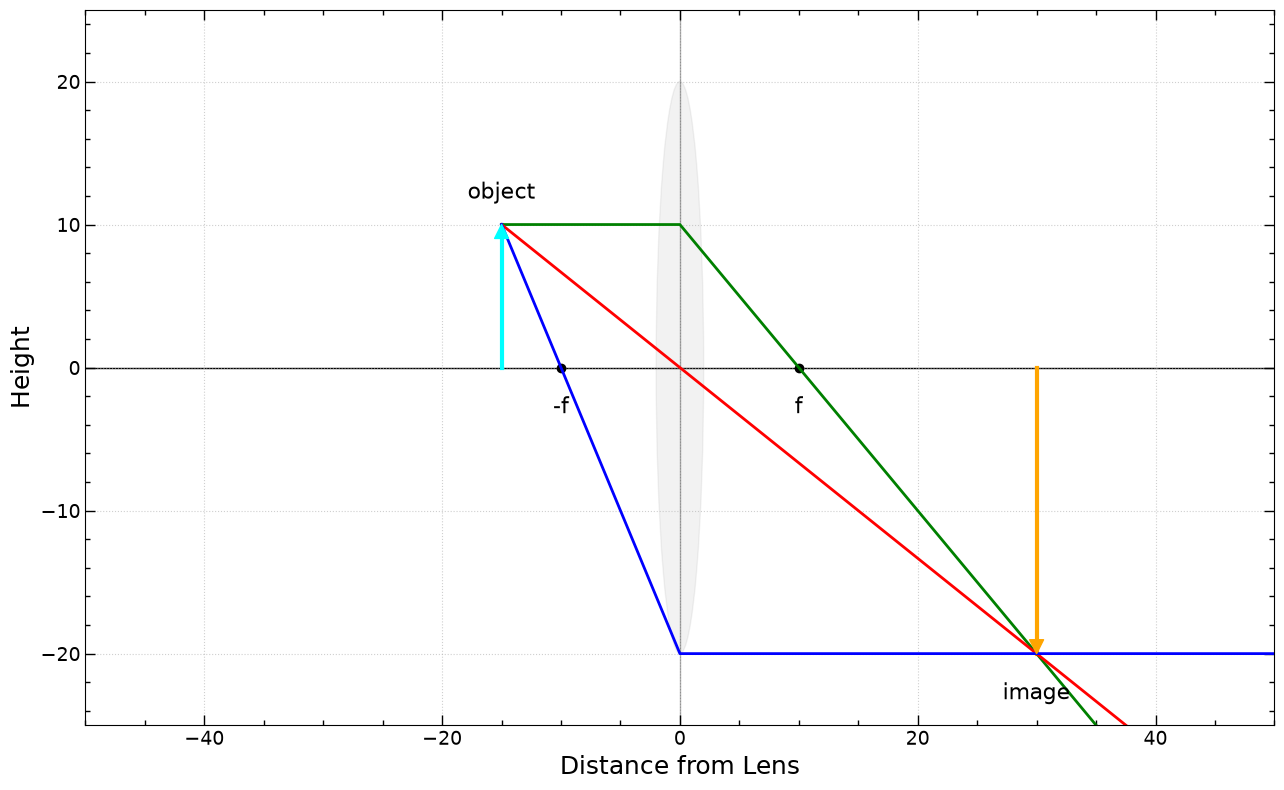

In [3]:
# --- Plotting ---
# create a figure containing a single set of axes
fig1, ax1 = plt.subplots(figsize=(8*1.618, 8))

# 1. Draw Lens (Approximated as an Ellipse)
lens = patches.Ellipse((0, 0), width=4, height=40, angle=0, 
                       color='gray', alpha=0.1, label='Lens')
ax1.add_patch(lens)
ax1.axvline(0, color='black', linestyle='-', alpha=0.3, linewidth=1) # Center line

# 2. Draw Focal Points
ax1.plot(f, 0, 'ko', markersize=6, label='Focal Point (f)')  
ax1.plot(-f, 0, 'ko', markersize=6, label='Focal Point (-f)')
ax1.text(f, -2, 'f', ha='center', va='top', fontsize=16)
ax1.text(-f, -2, '-f', ha='center', va='top', fontsize=16)

# 3. Draw Object (Green Arrow)
# We plot the line separate from the arrowhead for better control
l_obj = ax1.plot([-s_o, -s_o], [0, h_o], label='Object')
plt.setp(l_obj, linewidth=3, color='cyan')
# Add Arrowhead using annotate
ax1.annotate('', xy=(-s_o, h_o), xytext=(-s_o, 0),
             arrowprops=dict(facecolor='cyan', edgecolor='cyan', width=0, headwidth=10, headlength=10))

# 4. Draw Image (Red Arrow)
if np.isfinite(s_i):
    l_img = ax1.plot([s_i, s_i], [0, h_i], label='Image')
    plt.setp(l_img, linewidth=3, color='orange')
    # Add Arrowhead
    ax1.annotate('', xy=(s_i, h_i), xytext=(s_i, 0),
                 arrowprops=dict(facecolor='orange', edgecolor='orange', width=0, headwidth=10, headlength=10))

# 5. Draw Rays
ray_extent = 50 # Extent to draw rays to the right

if np.isfinite(s_i):
    # Ray 1: Parallel in, through focal point out
    # Segment 1: (-s_o, h_o) -> (0, h_o)
    # Segment 2: (0, h_o) -> through (f, 0) -> extend
    slope_1 = -h_o / f
    y_end_1 = h_o + slope_1 * (ray_extent - 0)
    
    l_ray1 = ax1.plot([-s_o, 0, ray_extent], [h_o, h_o, y_end_1], label='Ray 1')
    plt.setp(l_ray1, linewidth=2, color='green', linestyle='-')

    # Ray 2: Through optical center (undeflected)
    slope_2 = (0 - h_o) / (0 - (-s_o))
    y_end_2 = 0 + slope_2 * (ray_extent - 0)
    
    l_ray2 = ax1.plot([-s_o, ray_extent], [h_o, y_end_2], label='Ray 2')
    plt.setp(l_ray2, linewidth=2, color='red', linestyle='-')

    # Ray 3: Through front focal point, parallel out
    # Segment 1: (-s_o, h_o) -> (0, h_i) (passing through -f)
    # Segment 2: (0, h_i) -> (ray_extent, h_i)
    l_ray3 = ax1.plot([-s_o, 0, ray_extent], [h_o, h_i, h_i], label='Ray 3')
    plt.setp(l_ray3, linewidth=2, color='blue', linestyle='-')

ax1.text(-s_o, h_o*1.3, 'object', ha='center', va='top', fontsize=16)
ax1.text(s_i, h_i*1.1, 'image', ha='center', va='top', fontsize=16)

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both', direction="in", width=1, labelsize=14)
ax1.tick_params(which='major', length=7)
ax1.tick_params(which='minor', length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# set axes limits (Matched to your Plotly range)
ax1.set_xlim(-50, 50)
ax1.set_ylim(-25, 25)

# label the axes
ax1.set_xlabel("Distance from Lens", fontsize=18)
ax1.set_ylabel("Height", fontsize=18)

# Optical Axis line
ax1.axhline(0, color='black', linewidth=1, zorder=0)

# Add grid
ax1.grid(True, linestyle=':', alpha=0.6)

# Optional Legend
# ax1.legend(loc='upper right', fontsize=14, frameon=True)

# show the plot
plt.tight_layout()
plt.show()

## Make interactive with `ipywidgets`

In [4]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from matplotlib.animation import FuncAnimation

# This function takes an 'ax' (axes object) and the variables
def draw_lens_frame(ax, f, s_o, h_o):
    ax.clear() 
    
    # --- Physics ---
    if abs(s_o - f) < 0.1: 
        s_i, h_i = np.inf, np.inf
    else: 
        s_i = (f * s_o) / (s_o - f)
        h_i = (-s_i / s_o) * h_o
    
    # --- Styling ---
    plt.setp(ax.spines.values(), linewidth=2)
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=2, labelsize=14)
    ax.set_xlim(-50, 50)
    ax.set_ylim(-25, 25)
    ax.set_xlabel("Distance", fontsize=16)
    ax.set_ylabel("Height", fontsize=16)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.axhline(0, color='black', linewidth=2, zorder=0)
    ax.axvline(0, color='black', linestyle='-', alpha=0.3, linewidth=2)
    
    # --- Plot Elements ---
    lens = patches.Ellipse((0, 0), width=4, height=40, angle=0, color='gray', alpha=0.1)
    ax.add_patch(lens)
    
    # Focal points
    ax.plot([f, -f], [0, 0], 'ko', markersize=6)
    ax.text(f, -2, 'f', ha='center', va='top', fontsize=12)
    ax.text(-f, -2, '-f', ha='center', va='top', fontsize=12)
    
    # Object
    ax.plot([-s_o, -s_o], [0, h_o], color='cyan', linewidth=3)
    ax.annotate('', xy=(-s_o, h_o), xytext=(-s_o, 0), 
                arrowprops=dict(facecolor='cyan', edgecolor='cyan', headwidth=10))

    # Image
    if np.isfinite(s_i):
        ax.plot([s_i, s_i], [0, h_i], color='orange', linewidth=3)
        ax.annotate('', xy=(s_i, h_i), xytext=(s_i, 0), 
                    arrowprops=dict(facecolor='orange', edgecolor='orange', headwidth=10))
        
        # Rays
        ray_extent = 50
        
        # Ray 1 (Green): Parallel -> Focus
        slope_1 = -h_o / f
        ax.plot([-s_o, 0, ray_extent], [h_o, h_o, h_o + slope_1*ray_extent], 'g-', linewidth=2, alpha=0.8)
        
        # Ray 2 (Red): Center
        slope_2 = -h_o / s_o
        ax.plot([-s_o, ray_extent], [h_o, slope_2*ray_extent], 'r-', linewidth=2, alpha=0.8)
        
        # Ray 3 (Blue): Focus -> Parallel
        ax.plot([-s_o, 0, ray_extent], [h_o, h_i, h_i], 'b-', linewidth=2, alpha=0.8)

        # Virtual Image Tracebacks
        if s_i < 0:
            ax.plot([0, s_i], [h_o, h_i], 'g--', linewidth=1.5, alpha=0.6)
            ax.plot([-s_o, s_i], [h_o, h_i], 'r--', linewidth=1.5, alpha=0.6)
            ax.plot([0, s_i], [h_i, h_i], 'b--', linewidth=1.5, alpha=0.6)
            ax.plot([-f, -s_o], [0, h_o], 'b:', linewidth=1, alpha=0.4)

# Create a figure specifically for the widget
fig_widget, ax_widget = plt.subplots(figsize=(9, 6))
fig_widget.canvas.header_visible = False

# Wrapper function for the widget
def widget_update(f, s_o, h_o):
    # We call our shared logic function, passing this specific axes
    draw_lens_frame(ax_widget, f, s_o, h_o)

widgets.interact(widget_update, 
                 f=widgets.FloatSlider(value=10, min=5, max=20, step=0.5),
                 s_o=widgets.FloatSlider(value=15, min=1, max=45, step=0.5),
                 h_o=widgets.FloatSlider(value=10, min=-15, max=15, step=0.5));

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-01_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-01.html) (direct link: [ch03-01_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-01_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.